# 03 · Analysis: figures and tables


**Supplementary material to BioExcel-3 Deliverable D2.5**, *Final report on standards and recommendations for simulation, data generation, storage and mining*.


Part 3 of 3: 01 assemblies → 02 non-assemblies → **03 analysis**.


**Input:** the scored tables and issue configurations saved by notebooks 01 and 02 (`data/`).


**Output:** figures in `figures/`; the values behind each figure are printed below it.


**How to run:** run notebooks 01 and 02 first, then *Restart Kernel and Run All*.


**Contents**
1. [Setup](#sec1)
2. [Load scored data](#sec2)
3. [Issue prevalence](#sec3)
   - [3.1 Deuterium-labelled residues](#sec3-1)
4. [Tier distribution](#sec4)
   - [4.1 Scoring coverage](#sec4-1)
5. [Penalty distribution](#sec5)
   - [5.1 Penalty density, raw scale](#sec5-1)
6. [Penalty within tiers](#sec6)
   - [6.1 Check: smallest penalties in the *Needs structural repair* tier](#sec6-1)
7. [Penalty contribution by issue](#sec7)
8. [Environment](#sec8)

<a id="sec1"></a>
## 1. Setup

Imports, paths, figure style and issue labels.

In [1]:
import json
import platform
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
import seaborn as sns
from tabulate import tabulate

# --- Paths ---------------------------------------------------------------------
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# --- Figure style ----------------------------------------------------------------
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 8,
        "axes.labelsize": 8,
        "axes.titlesize": 9,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "legend.fontsize": 7,
        "axes.linewidth": 0.6,
        "grid.linewidth": 0.4,
        "lines.linewidth": 1.0,
        "patch.linewidth": 0.6,
        "pdf.fonttype": 42,  
        "ps.fonttype": 42,
    }
)

# --- Palettes and labels -----------------------------------------------------------
STRUCTURE_PALETTE = {
    "Assembly": "#1B365D",      # navy
    "Non-Assembly": "#0D9488",  # teal
}
COLOR_MAP = STRUCTURE_PALETTE

# Tier order, best to worst
TIER_ORDER = [
    "MD-ready as deposited",
    "MD-ready with system modification",
    "Needs structural repair",
    "Not MD-ready (major defect)",
    "Unscored (missing size data)",
]

DEFECT_NAME_MAP = {
    "altloc_count": "Alternate Conformations",
    "sidechain_missing_count": "Missing Sidechains",
    "missing_atoms_count": "Missing Backbone Atoms",
    "backbone_breaks_count": "Backbone Breaks",
    "sidechain_unknown_count": "Unknown Sidechains",
    "side_chirals_count": "Sidechain Chiral Issues",
    "bck_chirals_count": "Backbone Chiral Issues",
    "cis_count": "Cis Peptides",
    "amide_count": "Amide Issues",
    "severe_clashes_count": "Severe Clashes / Covalent",
    "apolar_clashes_count": "Apolar Clashes",
    "num_models": "Multiple Models",
    "num_ligands": "Non-standard Residues /\n Ligands (combined)",  # combined; split by type in the ** rows
    "num_ionizable": "Ionizable Groups",
    "deuterium_residue_count": "Deuterium-Labeled H (Neutron)",
    "sequence_mismatch_count": "Sequence Micro-heterogeneity",
    "num_histidines_ionizable": "Histidine Protonation/Tautomer",
    "disulfide_bnds": "Disulfide Bridges",
    "contacting_water_count": "Structural Water Contacts",
    # Issue 4 split by type (prevalence only, not weighted)
    "nonstandard_residue_count": "** Non-standard Residues",
    "metal_ion_count": "** Metal Ions",
    "small_molecule_ligand_count": "** Small-Molecule Ligands",
}

<a id="sec2"></a>
## 2. Load scored data

Reads the outputs of notebooks 01 and 02. The severity weights are taken from the saved issue configurations, so the penalty breakdown in Section 7 uses exactly the weights used for scoring.

In [2]:
# --- Scored tables (notebooks 01 and 02) ------------------------------------------
ASM_ranked = pd.read_parquet(DATA_DIR / "assembly_md_readiness_ranked.parquet")
ASU_scored = pd.read_parquet(DATA_DIR / "non_assembly_md_readiness_scored.parquet")

# --- Severity weights used for scoring (saved by notebooks 01 and 02) ----------------
with open(DATA_DIR / "assembly_issue_config.json") as fh:
    ASM_ISSUE_CONFIG = json.load(fh)
with open(DATA_DIR / "non_assembly_issue_config.json") as fh:
    ASU_ISSUE_CONFIG = json.load(fh)
assert ASM_ISSUE_CONFIG == ASU_ISSUE_CONFIG, "Assembly and non-assembly configurations differ"

ASM_WEIGHTS_SERIES = pd.Series({f: cfg["weight"] for f, cfg in ASM_ISSUE_CONFIG.items()})
ASU_WEIGHTS_SERIES = pd.Series({f: cfg["weight"] for f, cfg in ASU_ISSUE_CONFIG.items()})
MODELS_FLAG_WEIGHT = ASU_WEIGHTS_SERIES["num_models"]

# --- Issue fields -------------------------------------------------------------------------
RESIDUE_BASIS_FIELDS = [
    "altloc_count", "sidechain_missing_count", "missing_atoms_count",
    "backbone_breaks_count", "sidechain_unknown_count", "side_chirals_count",
    "bck_chirals_count", "cis_count", "amide_count",
    "disulfide_bnds", "num_ligands", "num_ionizable", "num_histidines_ionizable", "deuterium_residue_count",
    "sequence_mismatch_count",
]
ATOM_BASIS_FIELDS = ["severe_clashes_count", "apolar_clashes_count", "contacting_water_count"]

DEFECT_FIELDS = RESIDUE_BASIS_FIELDS + ATOM_BASIS_FIELDS

# Issue 4 split by type: not weighted (num_ligands carries the penalty), so kept
# separate from DEFECT_FIELDS. Used for prevalence only.
LIGAND_DECOMPOSITION_FIELDS = ["nonstandard_residue_count", "metal_ion_count", "small_molecule_ligand_count"]

# --- Combined table: one row per structure, tagged by type -------------------------------
ranked_tagged = ASM_ranked.assign(structure_type="Assembly")
scored_tagged = ASU_scored.assign(structure_type="Non-Assembly")

shared_cols = [
    "structure_type",
    "tier",
    "md_readiness_penalty",
    "fully_scored",
] + DEFECT_FIELDS + LIGAND_DECOMPOSITION_FIELDS

combined = pd.concat(
    [ranked_tagged[shared_cols], scored_tagged[shared_cols]],
    ignore_index=True,
)
combined["tier"] = pd.Categorical(
    combined["tier"], categories=TIER_ORDER, ordered=True
)
combined["log_penalty"] = np.log1p(combined["md_readiness_penalty"])

scored_only = combined[combined["fully_scored"]].copy()

print(tabulate(combined["structure_type"].value_counts().rename("structures").to_frame(), headers="keys", tablefmt="psql"))

+------------------+--------------+
| structure_type   |   structures |
|------------------+--------------|
| Assembly         |       297328 |
| Non-Assembly     |       247085 |
+------------------+--------------+


<a id="sec3"></a>
## 3. Issue prevalence

Percentage of structures with at least one occurrence of each issue. Rows marked ** split the combined ligand count (Issue 4) by type.

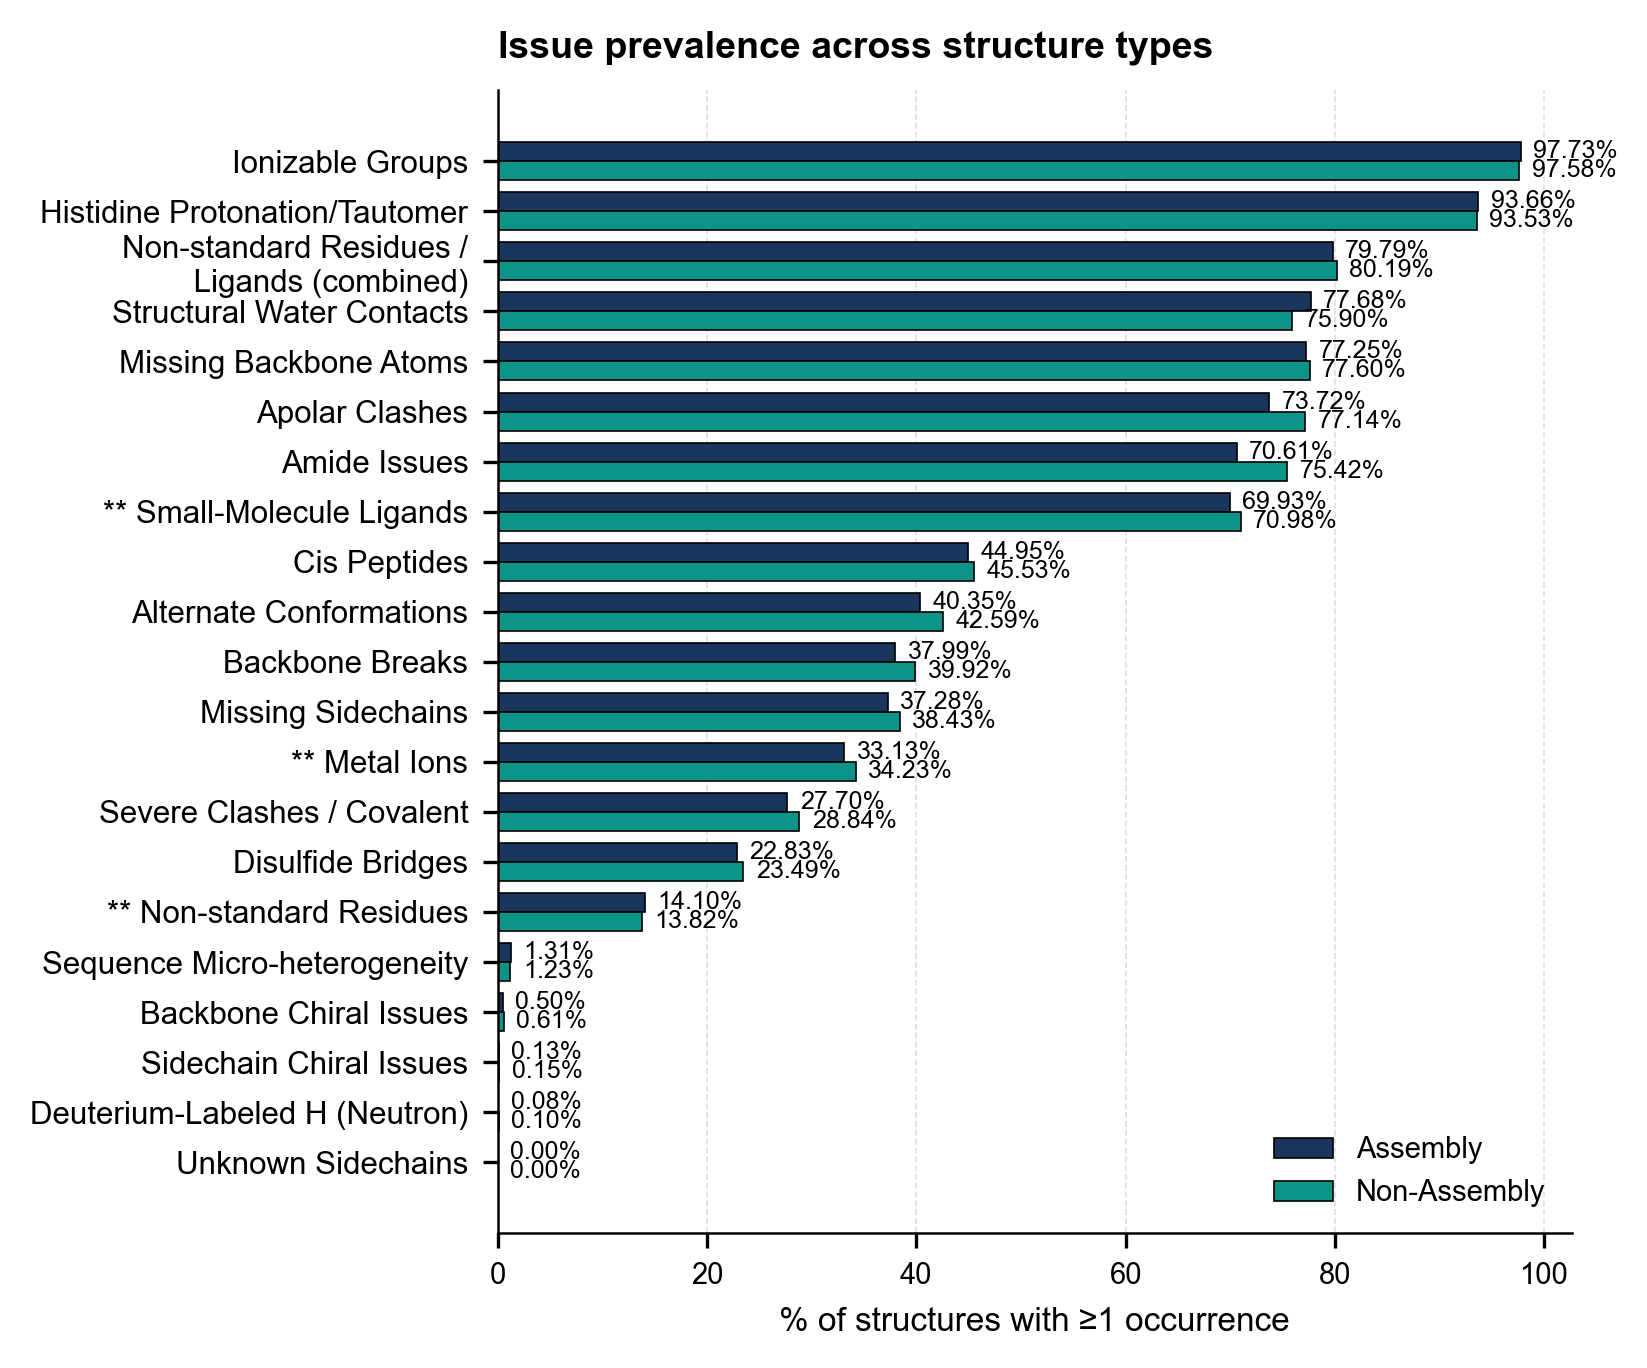

In [3]:
# --- Issue prevalence ------------------------------------------------------------
prev_df = (
    combined.groupby("structure_type")[DEFECT_FIELDS]
    .apply(lambda g: (g > 0).mean() * 100)
    .T.sort_values("Assembly", ascending=True)
)

# Issue 4 split by type, shown next to the combined num_ligands bar
ligand_prev_df = (
    combined.groupby("structure_type")[LIGAND_DECOMPOSITION_FIELDS]
    .apply(lambda g: (g > 0).mean() * 100)
    .T
)
prev_df = pd.concat([prev_df, ligand_prev_df]).sort_values("Assembly", ascending=True)

prev_df.index = [DEFECT_NAME_MAP.get(i, i) for i in prev_df.index]

fig, ax = plt.subplots(figsize=(5.5, 4.6), dpi=300)

y = np.arange(len(prev_df))
height = 0.38

rects_asm = ax.barh(
    y + height / 2,
    prev_df["Assembly"],
    height,
    label="Assembly",
    color=STRUCTURE_PALETTE["Assembly"],
    edgecolor="black",
    linewidth=0.4,
)
rects_asu = ax.barh(
    y - height / 2,
    prev_df["Non-Assembly"],
    height,
    label="Non-Assembly",
    color=STRUCTURE_PALETTE["Non-Assembly"],
    edgecolor="black",
    linewidth=0.4,
)

# Bar labels
ax.bar_label(rects_asm, fmt="%.2f%%", padding=3, fontsize=6)
ax.bar_label(rects_asu, fmt="%.2f%%", padding=3, fontsize=6)

ax.set_yticks(y)
ax.set_yticklabels(prev_df.index, fontsize=7.5)
ax.set_xlabel("% of structures with ≥1 occurrence")
ax.set_title(
    "Issue prevalence across structure types",
    fontweight="bold",
    loc="left",
    pad=8,
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.xaxis.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.savefig(FIG_DIR / "issue_prevalence.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

In [4]:
# --- Prevalence values (% of structures), most prevalent first ---------------------

prevalence_table = prev_df[["Assembly", "Non-Assembly"]].sort_values("Assembly", ascending=False).round(2)

prevalence_table_formatted = prevalence_table.map(lambda x: f"{x:.2f}%")

print(tabulate(prevalence_table_formatted, headers=["Issue Type", "Assembly", "Non-Assembly"], tablefmt="psql"))

+--------------------------------+------------+----------------+
| Issue Type                     | Assembly   | Non-Assembly   |
|--------------------------------+------------+----------------|
| Ionizable Groups               | 97.73%     | 97.58%         |
| Histidine Protonation/Tautomer | 93.66%     | 93.53%         |
| Non-standard Residues /        | 79.79%     | 80.19%         |
|  Ligands (combined)            |            |                |
| Structural Water Contacts      | 77.68%     | 75.90%         |
| Missing Backbone Atoms         | 77.25%     | 77.60%         |
| Apolar Clashes                 | 73.72%     | 77.14%         |
| Amide Issues                   | 70.61%     | 75.42%         |
| ** Small-Molecule Ligands      | 69.93%     | 70.98%         |
| Cis Peptides                   | 44.95%     | 45.53%         |
| Alternate Conformations        | 40.35%     | 42.59%         |
| Backbone Breaks                | 37.99%     | 39.92%         |
| Missing Sidechains     

<a id="sec3-1"></a>
### 3.1 Deuterium-labelled residues

Number and share of structures with at least one deuterium-labelled residue.

In [5]:
positive_rows_count = (scored_only['deuterium_residue_count'] > 0).sum()
print(f"Structures with deuterium-labelled residues: {positive_rows_count}")

print(scored_only.groupby('structure_type')['deuterium_residue_count'].apply(lambda x: (x > 0).sum()))

positive_rows_percentage = (scored_only['deuterium_residue_count'] > 0).mean() * 100
print(f"Share of all scored structures: {positive_rows_percentage:.4f}%")

Structures with deuterium-labelled residues: 485
structure_type
Assembly        246
Non-Assembly    239
Name: deuterium_residue_count, dtype: int64
Share of all scored structures: 0.0891%


<a id="sec4"></a>
## 4. Tier distribution

Share of structures in each MD-readiness tier, with the counts below the figure.

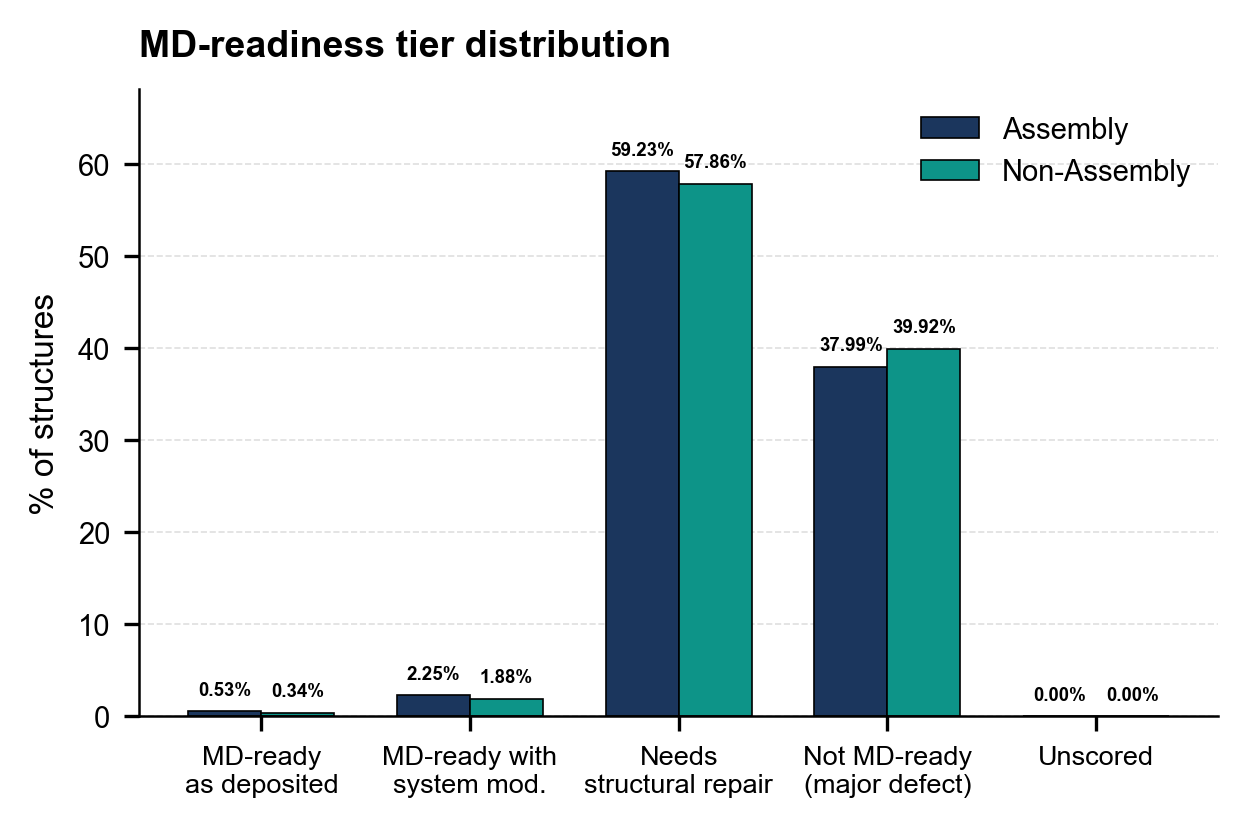

+------------------+-----------------------------------+---------+-------+
| structure_type   | tier                              |   count |   pct |
|------------------+-----------------------------------+---------+-------|
| Assembly         | MD-ready as deposited             |    1567 |  0.53 |
| Assembly         | MD-ready with system modification |    6691 |  2.25 |
| Assembly         | Needs structural repair           |  176117 | 59.23 |
| Assembly         | Not MD-ready (major defect)       |  112953 | 37.99 |
| Non-Assembly     | MD-ready as deposited             |     841 |  0.34 |
| Non-Assembly     | MD-ready with system modification |    4645 |  1.88 |
| Non-Assembly     | Needs structural repair           |  142960 | 57.86 |
| Non-Assembly     | Not MD-ready (major defect)       |   98639 | 39.92 |
+------------------+-----------------------------------+---------+-------+


In [6]:
# --- Tier distribution ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(4.2, 2.8), dpi=300)

tier_props = (
    combined.groupby("structure_type")["tier"]
    .value_counts(normalize=True)
    .rename("proportion")
    .reset_index()
)

x = np.arange(len(TIER_ORDER))
width = 0.35

asm_props = (
    tier_props[tier_props["structure_type"] == "Assembly"]
    .set_index("tier")
    .reindex(TIER_ORDER)["proportion"]
    .fillna(0)
    * 100
)
asu_props = (
    tier_props[tier_props["structure_type"] == "Non-Assembly"]
    .set_index("tier")
    .reindex(TIER_ORDER)["proportion"]
    .fillna(0)
    * 100
)

rects1 = ax.bar(
    x - width / 2,
    asm_props,
    width,
    label="Assembly",
    color=STRUCTURE_PALETTE["Assembly"],
    edgecolor="black",
    linewidth=0.4,
)
rects2 = ax.bar(
    x + width / 2,
    asu_props,
    width,
    label="Non-Assembly",
    color=STRUCTURE_PALETTE["Non-Assembly"],
    edgecolor="black",
    linewidth=0.4,
)

# Bar labels
ax.bar_label(rects1, fmt="%.2f%%", padding=3, fontsize=4.5, fontweight="bold")
ax.bar_label(rects2, fmt="%.2f%%", padding=3, fontsize=4.5, fontweight="bold")

ax.set_ylabel("% of structures")
ax.set_title(
    "MD-readiness tier distribution", fontweight="bold", loc="left", pad=8
)
ax.set_xticks(x)
ax.set_xticklabels(
    ["MD-ready\nas deposited", "MD-ready with\nsystem mod.", "Needs\nstructural repair", "Not MD-ready\n(major defect)", "Unscored"],
    rotation=0,
    ha="center",
    fontsize=6.5,
)

# Headroom for bar labels
max_height = max(asm_props.max(), asu_props.max())
ax.set_ylim(0, max_height * 1.15)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.yaxis.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right")

plt.tight_layout()
plt.savefig(FIG_DIR / "tier_distribution.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# --- Counts and percentages per tier -------------------------------------------
tier_summary = (
    combined.groupby(["structure_type", "tier"])
    .size()
    .rename("count")
    .reset_index()
)
tier_summary["pct"] = (
    tier_summary.groupby("structure_type")["count"].transform(lambda s: s / s.sum() * 100)
).round(2)
print(tabulate(tier_summary, headers="keys", tablefmt="psql", showindex=False))

<a id="sec4-1"></a>
### 4.1 Scoring coverage

Share of structures with a complete penalty (residue and atom counts both available).

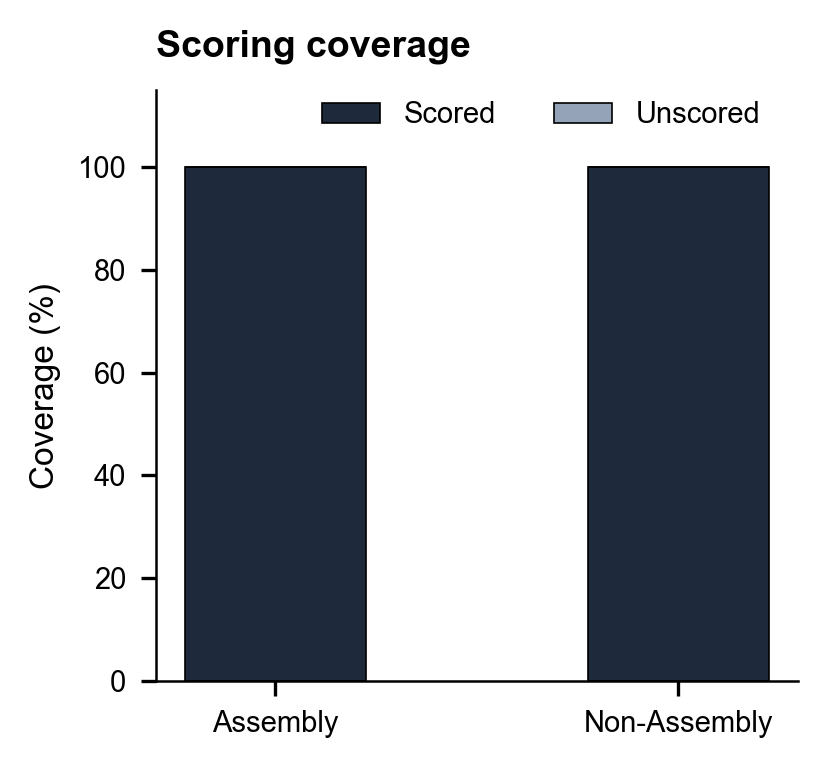

+------------------+--------+
| structure_type   |   True |
|------------------+--------|
| Assembly         | 297328 |
| Non-Assembly     | 247085 |
+------------------+--------+


In [7]:
# --- Share of fully scored structures ------------------------------------------
fig, ax = plt.subplots(figsize=(2.8, 2.6), dpi=300)
coverage = (
    combined.groupby("structure_type")["fully_scored"]
    .value_counts(normalize=True)
    .rename("proportion")
    .reset_index()
)
coverage["fully_scored"] = coverage["fully_scored"].map(
    {True: "Scored", False: "Unscored"}
)

x_cov = np.arange(2)
struct_types = ["Assembly", "Non-Assembly"]

scored_vals = [
    next(iter(coverage[(coverage["structure_type"] == st) & (coverage["fully_scored"] == "Scored")]["proportion"]), 0.0) * 100
    for st in struct_types
]

unscored_vals = [
    next(iter(coverage[(coverage["structure_type"] == st) & (coverage["fully_scored"] == "Unscored")]["proportion"]), 0.0) * 100
    for st in struct_types
]

b1 = ax.bar(
    x_cov,
    scored_vals,
    width=0.45,
    label="Scored",
    color="#1E293B",
    edgecolor="black",
    linewidth=0.4,
)
b2 = ax.bar(
    x_cov,
    unscored_vals,
    width=0.45,
    bottom=scored_vals,
    label="Unscored",
    color="#94A3B8",
    edgecolor="black",
    linewidth=0.4,
)

ax.set_ylabel("Coverage (%)")
ax.set_title("Scoring coverage", fontweight="bold", loc="left", pad=8)
ax.set_xticks(x_cov)
ax.set_xticklabels(struct_types)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylim(0, 115)
ax.legend(
    frameon=False,
    loc="lower center",
    bbox_to_anchor=(0.6, 0.89),
    ncol=2,
)

plt.tight_layout()
plt.show()
plt.close()

print(tabulate(combined.groupby("structure_type")["fully_scored"].value_counts().unstack(fill_value=0),
               headers="keys", tablefmt="psql"))

<a id="sec5"></a>
## 5. Penalty distribution

Distribution of the penalty for fully scored structures (log scale and cumulative), followed by summary statistics.

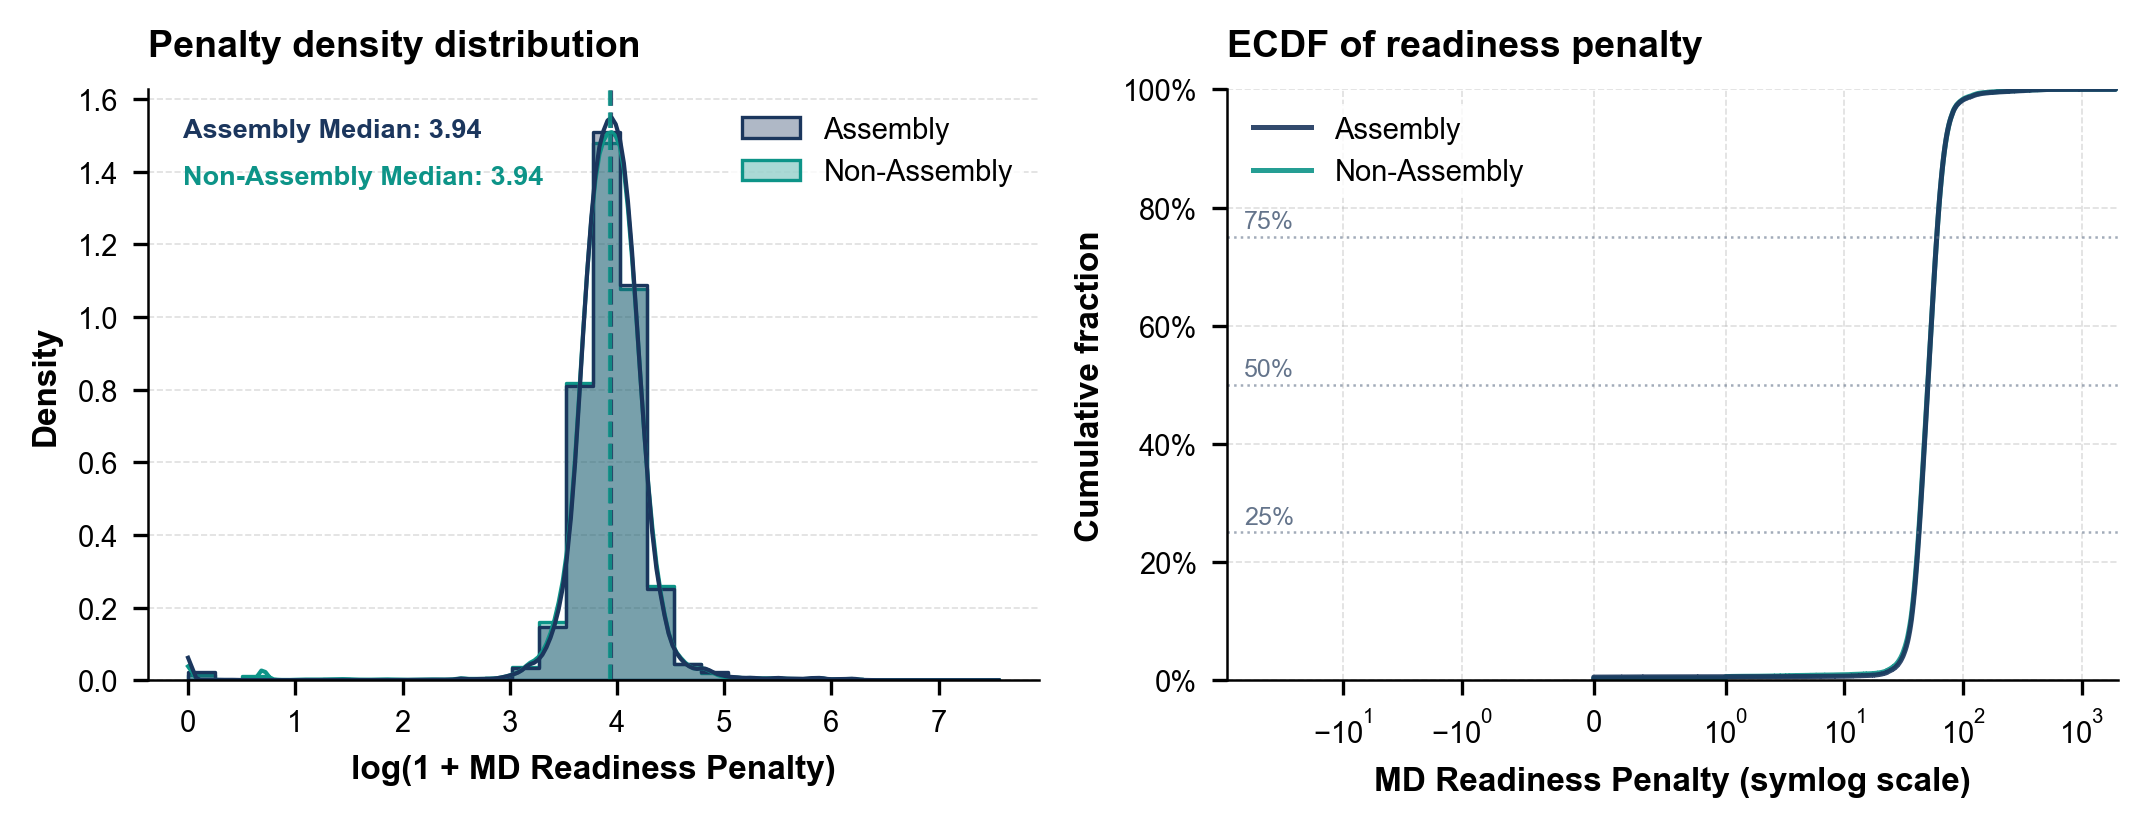

Penalty distribution statistics
+------------------+---------+--------+-------+-------+-------+-------+-------+---------+----------+
| structure_type   |   count |   mean |   std |   min |    Q1 |   50% |    Q3 |     max |   median |
|------------------+---------+--------+-------+-------+-------+-------+-------+---------+----------|
| Assembly         |  297328 |  53.47 | 26.23 |     0 | 42.48 | 50.44 | 59.91 | 1916.99 |    50.44 |
| Non-Assembly     |  247085 |  52.99 | 24.75 |     0 | 42.19 | 50.28 | 59.88 | 1916.99 |    50.28 |
+------------------+---------+--------+-------+-------+-------+-------+-------+---------+----------+


In [8]:
# --- Log-penalty density and ECDF ----------------------------------------------
# Two-column width (183 mm)
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.8), dpi=300)

# =============================================================================
# Subplot 1: Penalty Density Distribution (Log Scale)
# =============================================================================
sns.histplot(
    data=scored_only,
    x="log_penalty",
    hue="structure_type",
    stat="density",
    common_norm=False,
    kde=True,
    element="step",
    ax=axes[0],
    palette=COLOR_MAP,
    linewidth=0.8,
    alpha=0.35,
    bins=30,
)

# Dynamic median annotations using relative axis placement
groups = list(COLOR_MAP.keys())
for i, stype in enumerate(groups):
    if stype in scored_only["structure_type"].values:
        subset = scored_only[scored_only["structure_type"] == stype]
        median_val = subset["log_penalty"].median()
        color = COLOR_MAP[stype]

        # Median reference line
        axes[0].axvline(
            median_val, color=color, linestyle="--", linewidth=1.0, alpha=0.85
        )

        # Relative axis coordinates prevent text clipping across datasets
        axes[0].text(
            0.04,
            0.92 - i * 0.08,
            f"{stype} Median: {median_val:.2f}",
            transform=axes[0].transAxes,
            color=color,
            fontweight="bold",
            fontsize=6.5,
        )

axes[0].set_xlabel("log(1 + MD Readiness Penalty)", fontweight="bold")
axes[0].set_ylabel("Density", fontweight="bold")
axes[0].set_title(
    "Penalty density distribution", fontweight="bold", loc="left", pad=8
)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].yaxis.grid(True, linestyle="--", alpha=0.4)
axes[0].set_axisbelow(True)

# Clean legend formatting
leg0 = axes[0].get_legend()
if leg0:
    leg0.set_title(None)
    leg0.get_frame().set_linewidth(0)

# =============================================================================
# Subplot 2: Symlog ECDF (Handles zeros & large power-law tails)
# =============================================================================
sns.ecdfplot(
    data=scored_only,
    x="md_readiness_penalty",
    hue="structure_type",
    ax=axes[1],
    palette=COLOR_MAP,
    linewidth=1.2,
    alpha=0.9,
)

# Apply symlog to resolve extreme skewness around 0 while showing large tails
axes[1].set_xscale("symlog", linthresh=1.0)

# Horizontal quartile guide lines
for pct in [0.25, 0.5, 0.75]:
    axes[1].axhline(pct, color="#64748B", linestyle=":", linewidth=0.6, alpha=0.6)
    axes[1].text(
        0.02,
        pct + 0.015,
        f"{int(pct*100)}%",
        transform=axes[1].get_yaxis_transform(),
        fontsize=6,
        color="#64748B",
    )

axes[1].set_xlabel("MD Readiness Penalty (symlog scale)", fontweight="bold")
axes[1].set_ylabel("Cumulative fraction", fontweight="bold")
axes[1].set_title(
    "ECDF of readiness penalty", fontweight="bold", loc="left", pad=8
)
axes[1].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].yaxis.grid(True, linestyle="--", alpha=0.4)
axes[1].xaxis.grid(True, linestyle="--", alpha=0.4)
axes[1].set_axisbelow(True)

leg1 = axes[1].get_legend()
if leg1:
    leg1.set_title(None)
    leg1.get_frame().set_linewidth(0)

plt.tight_layout()
plt.savefig(FIG_DIR / "penalty_density_log_ecdf.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# --- Penalty summary statistics -------------------------------------------------
print("Penalty distribution statistics")
penalty_stats = scored_only.groupby("structure_type")[
    "md_readiness_penalty"
].describe()[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
penalty_stats["median"] = penalty_stats["50%"]
penalty_stats = penalty_stats.rename(columns={"25%": "Q1", "75%": "Q3"})
print(tabulate(penalty_stats.round(2), headers="keys", tablefmt="psql"))

<a id="sec5-1"></a>
### 5.1 Penalty density, raw scale

The same distribution without the log transform, showing the long tail of high penalties.

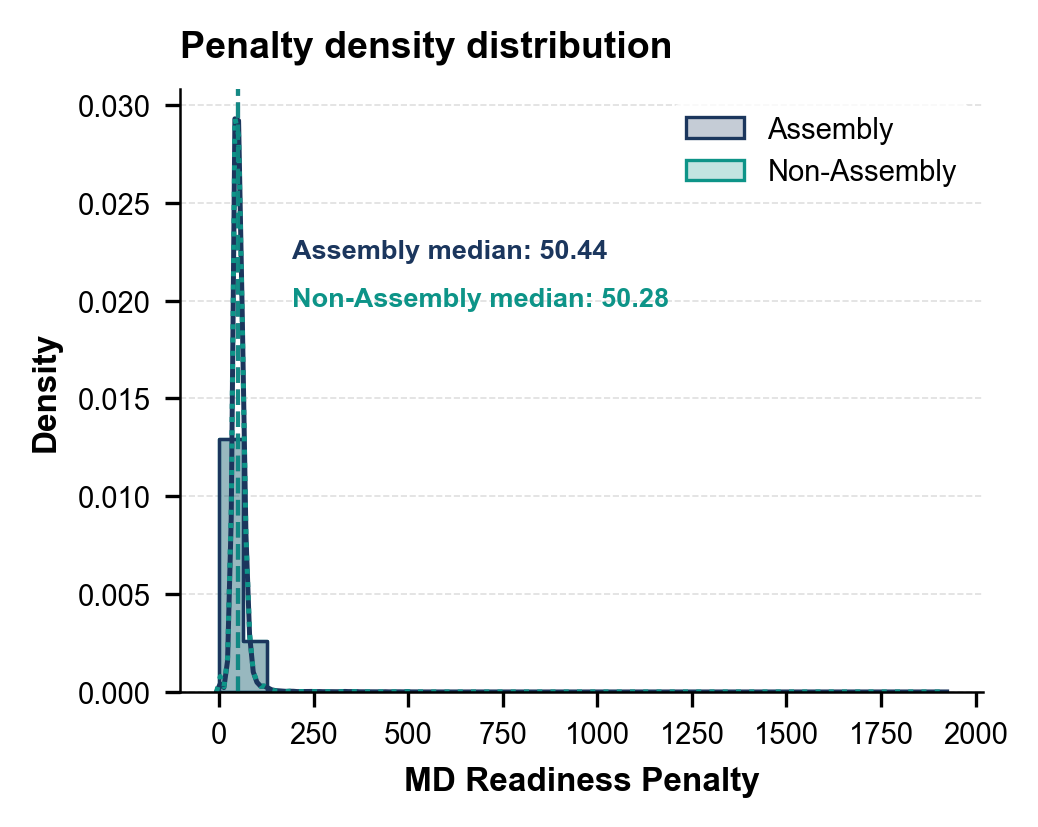

In [9]:
# --- Penalty density, raw scale -------------------------------------------------
fig1, ax1 = plt.subplots(figsize=(3.5, 2.8), dpi=300)

# Histogram only
sns.histplot(
    data=scored_only,
    x="md_readiness_penalty",
    hue="structure_type",
    stat="density",
    common_norm=False,
    kde=False,
    element="step",
    ax=ax1,
    palette=COLOR_MAP,
    linewidth=0.8,
    alpha=0.25,
    bins=30,
)

# Add KDEs separately so we can control line styles
for stype in ["Assembly", "Non-Assembly"]:
    subset = scored_only[
        scored_only["structure_type"] == stype
    ]["md_readiness_penalty"].dropna()

    sns.kdeplot(
        data=subset,
        ax=ax1,
        color=COLOR_MAP[stype],
        linewidth=1.2,
        linestyle="-" if stype == "Assembly" else ":",
        fill=False,
    )

# Median reference lines and callout annotations
groups = list(COLOR_MAP.keys())
for i, stype in enumerate(groups):
    if stype in scored_only["structure_type"].values:
        subset = scored_only[scored_only["structure_type"] == stype]
        median_val = subset["md_readiness_penalty"].median()
        color = COLOR_MAP[stype]

        ax1.axvline(
            median_val,
            color=color,
            linestyle="--",
            linewidth=1.0,
            alpha=0.85,
        )

        ax1.text(
            0.14,
            0.72 - i * 0.08,
            f"{stype} median: {median_val:.2f}",
            transform=ax1.transAxes,
            color=color,
            fontweight="bold",
            fontsize=6.5,
        )

ax1.set_xlabel("MD Readiness Penalty", fontweight="bold")
ax1.set_ylabel("Density", fontweight="bold")
ax1.set_title(
    "Penalty density distribution",
    fontweight="bold",
    loc="left",
    pad=8,
)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.yaxis.grid(True, linestyle="--", alpha=0.4)
ax1.set_axisbelow(True)

leg1 = ax1.get_legend()
if leg1:
    leg1.set_title(None)
    leg1.get_frame().set_linewidth(0)

plt.tight_layout()
plt.savefig(FIG_DIR / "penalty_density_raw.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

<a id="sec6"></a>
## 6. Penalty within tiers

Median (white point) and quartiles (black marks) of log(1 + penalty) per tier, with sample sizes.

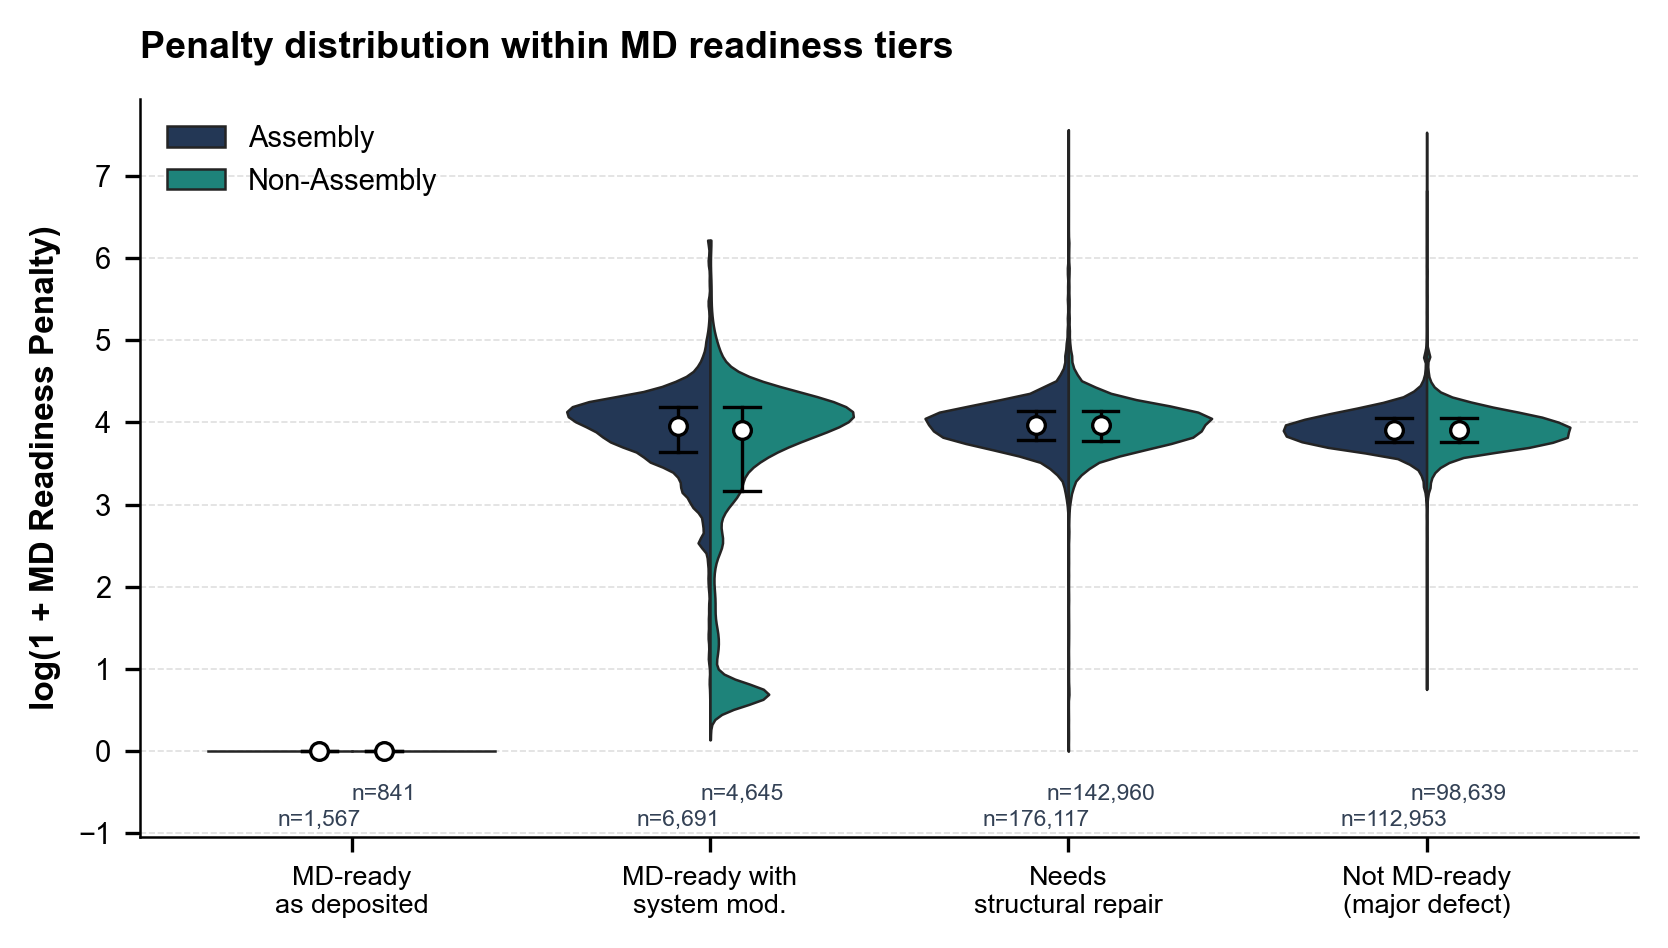

Penalty statistics by tier
+-------------------------------------------------------+---------+---------+----------+---------+--------+----------+---------+---------+
|                                                       |   count |    mean |   median |     std |    min |      max |      Q1 |      Q3 |
|-------------------------------------------------------+---------+---------+----------+---------+--------+----------+---------+---------|
| ('Assembly', 'MD-ready as deposited')                 |    1567 |  0      |   0      |  0      | 0      |    0     |  0      |  0      |
| ('Assembly', 'MD-ready with system modification')     |    6691 | 54.9775 |  51.5539 | 39.9522 | 0.1513 |  500     | 37.1398 | 65.2174 |
| ('Assembly', 'Needs structural repair')               |  176117 | 55.6212 |  51.8678 | 29.7423 | 0.0034 | 1916.99  | 43.0927 | 61.8441 |
| ('Assembly', 'Not MD-ready (major defect)')           |  112953 | 50.7683 |  48.8574 | 16.826  | 1.1225 | 1859.73  | 42.2048 | 56.852  |


In [10]:
# --- Penalty within tiers (split violins) ---------------------------------------
plot_tiers = [t for t in TIER_ORDER if t != "Unscored (missing size data)"]
plot_data = scored_only[scored_only["tier"].isin(plot_tiers)].copy()

fig, ax = plt.subplots(figsize=(5.6, 3.2), dpi=300)

# Seaborn >=0.13 uses density_norm="width"; fallback to scale="width" for older versions
try:
    violin = sns.violinplot(
        data=plot_data, x="tier", y="log_penalty", hue="structure_type",
        order=plot_tiers, split=True, ax=ax, palette=STRUCTURE_PALETTE,
        inner=None, linewidth=0.6, density_norm="width", bw_adjust=0.6, cut=0
    )
except TypeError:
    violin = sns.violinplot(
        data=plot_data, x="tier", y="log_penalty", hue="structure_type",
        order=plot_tiers, split=True, ax=ax, palette=STRUCTURE_PALETTE,
        inner=None, linewidth=0.6, scale="width", bw_adjust=0.6, cut=0
    )

# --- Medians and quartiles --------------------------------------------------------
for i, tier in enumerate(plot_tiers):
    for j, stype in enumerate(["Assembly", "Non-Assembly"]):
        subset = plot_data[(plot_data["tier"] == tier) & (plot_data["structure_type"] == stype)]
        if len(subset) > 0:
            q1, median, q3 = subset["log_penalty"].quantile([0.25, 0.5, 0.75])

            # Position offset matching Seaborn split-violin width
            pos = i + (j - 0.5) * 0.18

            # Draw median dot
            ax.scatter(pos, median, color="white", edgecolor="black", s=18, zorder=5, linewidth=0.8)
            # Draw quartile horizontal lines & interquartile range line
            ax.plot([pos - 0.05, pos + 0.05], [q1, q1], color="black", linewidth=0.8, zorder=4)
            ax.plot([pos - 0.05, pos + 0.05], [q3, q3], color="black", linewidth=0.8, zorder=4)
            ax.plot([pos, pos], [q1, q3], color="black", linewidth=0.8, zorder=4)

# --- Sample sizes (n), with room below the violins ---------------------------------
ymin, ymax = ax.get_ylim()
ax.set_ylim(ymin - (ymax - ymin) * 0.08, ymax)

for i, tier in enumerate(plot_tiers):
    for j, stype in enumerate(["Assembly", "Non-Assembly"]):
        subset = plot_data[(plot_data["tier"] == tier) & (plot_data["structure_type"] == stype)]
        n = len(subset)
        if n > 0:
            pos = i + (j - 0.5) * 0.18
            # x in data coordinates, y as a fraction of the axis height; labels staggered
            y_pos = 0.01 if stype == "Assembly" else 0.045
            ax.text(
                pos, y_pos, f"n={n:,}",
                transform=ax.get_xaxis_transform(),
                fontsize=5.5,
                ha="center",
                va="bottom",
                color="#334155",
            )

# --- Labels, spines and grid -------------------------------------------------------
ax.set_ylabel("log(1 + MD Readiness Penalty)", fontweight="bold")
ax.set_xlabel("")
ax.set_title("Penalty distribution within MD readiness tiers", fontweight="bold", loc="left", pad=10)

ax.set_xticks(range(len(plot_tiers)))
ax.set_xticklabels([
    "MD-ready\nas deposited",
    "MD-ready with\nsystem mod.",
    "Needs\nstructural repair",
    "Not MD-ready\n(major defect)",
], fontsize=6.5)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.yaxis.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

ax.legend(frameon=False, loc="upper left")

plt.tight_layout()
plt.savefig(FIG_DIR / "penalty_by_tier.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# --- Penalty statistics by tier ----------------------------------------------------
print("Penalty statistics by tier")
tier_stats = (
    plot_data.groupby(["structure_type", "tier"])["md_readiness_penalty"]
    .agg([
        "count", "mean", "median", "std", "min", "max",
        lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)
    ])
    .rename(columns={"<lambda_0>": "Q1", "<lambda_1>": "Q3"})
    .round(4)
)
print(tabulate(tier_stats, headers="keys", tablefmt="psql"))

<a id="sec6-1"></a>
### 6.1 Check: smallest penalties in the *Needs structural repair* tier

Every structure in this tier has at least one issue, so its penalty must be above zero. Values that round to 0.00 in the table above are small but positive.

In [11]:
repair = plot_data[plot_data["tier"] == "Needs structural repair"]

print("Structures in tier:", len(repair))
print("Exact zeros:", (repair["md_readiness_penalty"] == 0).sum())
print("Rounded zeros:", (repair["md_readiness_penalty"].round(2) == 0).sum())
print("Minimum:", repair["md_readiness_penalty"].min())

print("\nSmallest penalties:")
print(repair["md_readiness_penalty"].sort_values().head(10).to_string(index=False))

Structures in tier: 319077
Exact zeros: 0
Rounded zeros: 8
Minimum: 0.0033825110820733177

Smallest penalties:
0.003383
0.003383
0.004045
0.004045
0.004045
0.004045
0.004045
0.004045
0.012134
0.012134


<a id="sec7"></a>
## 7. Penalty contribution by issue

Each structure's penalty is split into its per-issue terms. The terms are summed over all structures, and each issue's share of the total is reported. A built-in check confirms that the terms add up to each structure's penalty.

In [12]:
# =============================================================================
# Share of the total penalty contributed by each issue
# (prevalence x number of occurrences x severity weight; fully scored rows only)
# =============================================================================

def compute_field_contributions(
    scored_df, weights_series, residue_basis_fields, atom_basis_fields,
    model_flag_weight=None, model_field="num_models",
):
    """
    Split md_readiness_penalty into its per-issue terms (one column per issue),
    computed exactly as in the scoring of notebooks 01 and 02.
    """
    df = scored_df[scored_df["fully_scored"]].copy()

    residue_denom = df["residue_count"].where(df["residue_count"] > 0)
    atom_denom = df["atoms_count"].where(df["atoms_count"] > 0)

    residue_contrib = (
        df[residue_basis_fields].div(residue_denom, axis=0) * 100
    ).mul(weights_series[residue_basis_fields], axis=1)

    atom_contrib = (
        df[atom_basis_fields].div(atom_denom, axis=0) * 100
    ).mul(weights_series[atom_basis_fields], axis=1)

    contrib = pd.concat([residue_contrib, atom_contrib], axis=1)

    if model_flag_weight is not None and model_field in df.columns:
        contrib[model_field] = (df[model_field].fillna(1) > 1).astype(int) * model_flag_weight

    # Check: the per-issue terms must add up to each row's md_readiness_penalty
    reconstructed = contrib.sum(axis=1)
    max_diff = (reconstructed - df["md_readiness_penalty"]).abs().max()
    assert max_diff < 1e-6, f"Contribution breakdown doesn't reconcile (max diff={max_diff})"

    return contrib

def rank_issue_contributions(contrib_df):
    """
    Summarise per-issue terms over all structures:
      - total_contribution:    summed penalty from this issue
      - pct_of_total_penalty:  the same, as % of the total penalty
      - n_structures_affected: structures where the issue contributes
      - mean_when_affected:    mean contribution in those structures
    """
    total = contrib_df.sum(skipna=True)
    grand_total = total.sum()
    affected = contrib_df.fillna(0) > 0

    summary = pd.DataFrame({
        "total_contribution": total.round(2),
        "pct_of_total_penalty": (total / grand_total * 100).round(2),
        "n_structures_affected": affected.sum(),
        "mean_when_affected": contrib_df.where(affected).mean().round(3),
    }).sort_values("total_contribution", ascending=False)

    return summary

# --- Run for both structure types ------------------------------------------
asm_contrib = compute_field_contributions(
    ASM_ranked, ASM_WEIGHTS_SERIES, RESIDUE_BASIS_FIELDS, ATOM_BASIS_FIELDS,
    model_flag_weight=MODELS_FLAG_WEIGHT,
)
asm_ranking = rank_issue_contributions(asm_contrib)

asu_contrib = compute_field_contributions(
    ASU_scored, ASU_WEIGHTS_SERIES, RESIDUE_BASIS_FIELDS, ATOM_BASIS_FIELDS,
    model_flag_weight=MODELS_FLAG_WEIGHT,
)
asu_ranking = rank_issue_contributions(asu_contrib)

print("=== Assemblies: penalty contribution by issue ===")
print(tabulate(asm_ranking, headers="keys", tablefmt="psql"))
print("\n=== Non-assemblies: penalty contribution by issue ===")
print(tabulate(asu_ranking, headers="keys", tablefmt="psql"))

=== Assemblies: penalty contribution by issue ===
+--------------------------+----------------------+------------------------+-------------------------+----------------------+
|                          |   total_contribution |   pct_of_total_penalty |   n_structures_affected |   mean_when_affected |
|--------------------------+----------------------+------------------------+-------------------------+----------------------|
| num_ionizable            |          6.01866e+06 |                  37.86 |                  290579 |               20.713 |
| contacting_water_count   |          4.81358e+06 |                  30.28 |                  230971 |               20.841 |
| num_ligands              |          1.66131e+06 |                  10.45 |                  237252 |                7.002 |
| num_histidines_ionizable |     997613           |                   6.28 |                  278478 |                3.582 |
| altloc_count             |     777269           |                 

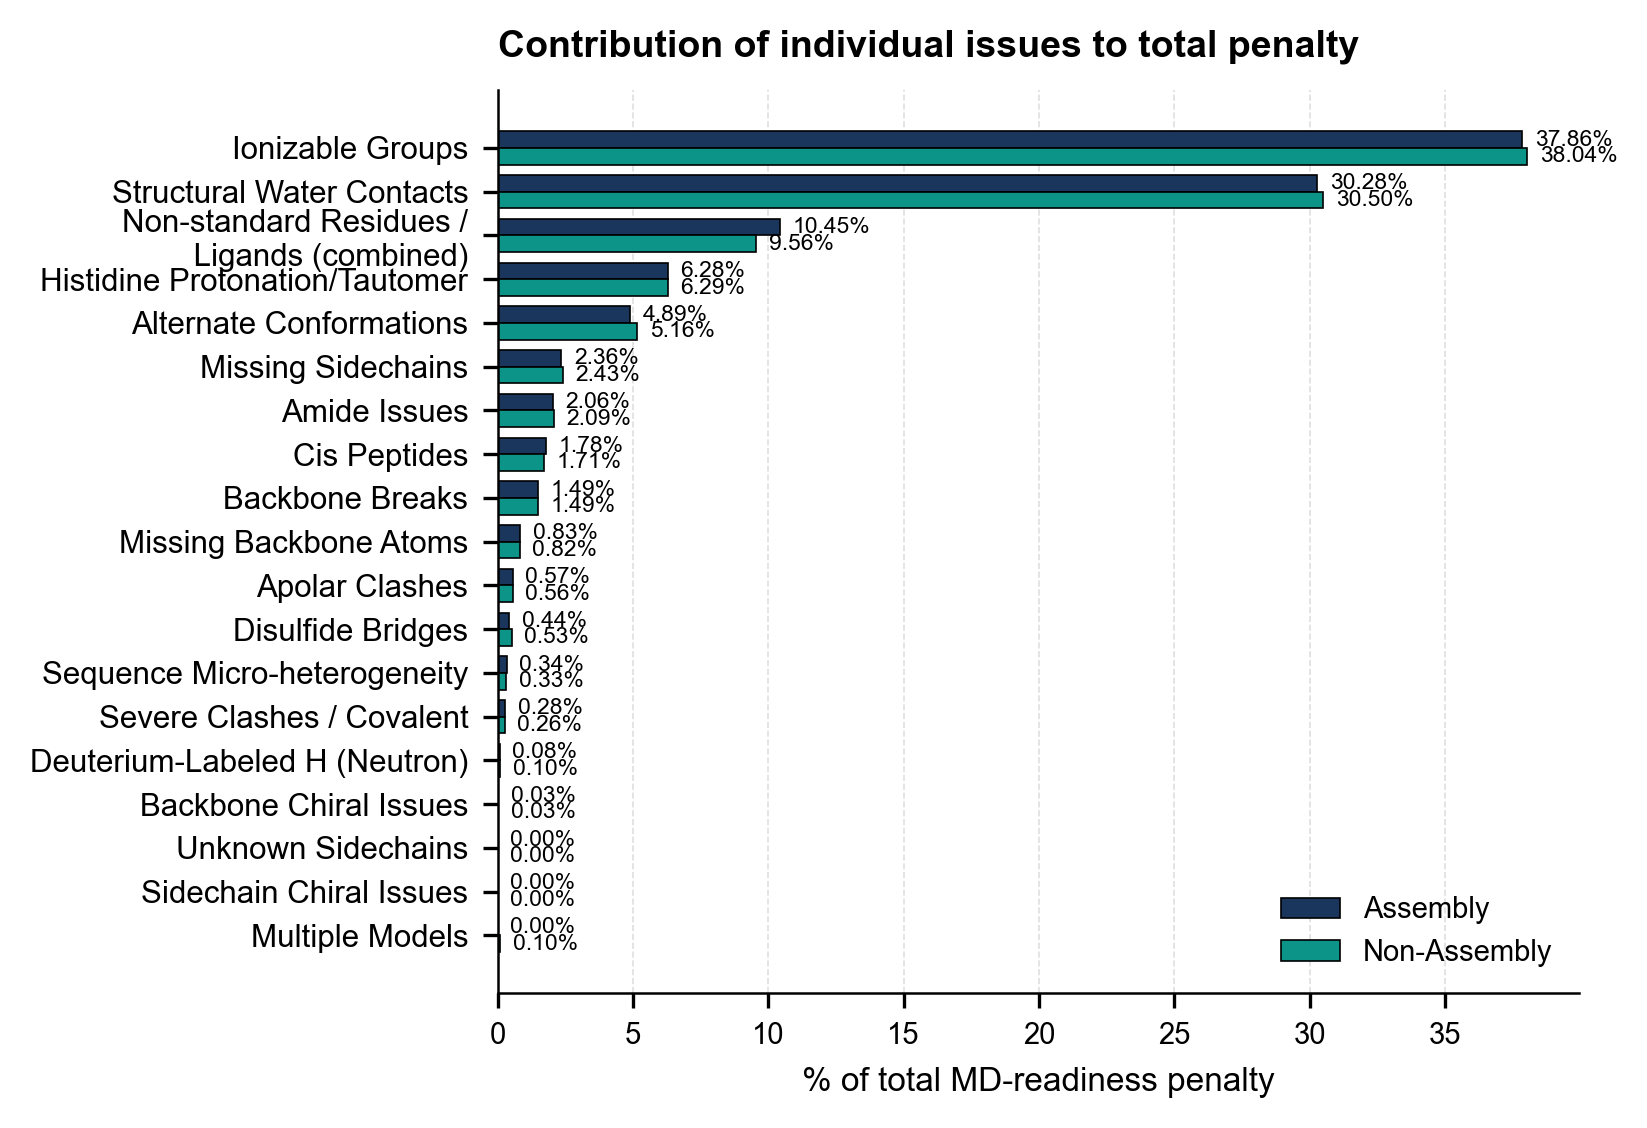

In [13]:
# --- Contribution of each issue to the total penalty ------------------------------
share = pd.DataFrame({
    "Assembly": asm_ranking["pct_of_total_penalty"],
    "Non-Assembly": asu_ranking["pct_of_total_penalty"],
})

# Readable issue names
share.index = [
    DEFECT_NAME_MAP.get(i, i)
    for i in share.index
]

# Ordered by Assembly contribution
share = share.sort_values("Assembly", ascending=True)

fig, ax = plt.subplots(figsize=(5.5, 3.8), dpi=300)

y = np.arange(len(share))
height = 0.38

rects_asm = ax.barh(
    y + height / 2,
    share["Assembly"],
    height,
    label="Assembly",
    color=STRUCTURE_PALETTE["Assembly"],
    edgecolor="black",
    linewidth=0.4,
)

rects_asu = ax.barh(
    y - height / 2,
    share["Non-Assembly"],
    height,
    label="Non-Assembly",
    color=STRUCTURE_PALETTE["Non-Assembly"],
    edgecolor="black",
    linewidth=0.4,
)

# Bar labels
ax.bar_label(rects_asm, fmt="%.2f%%", padding=3, fontsize=5.5)
ax.bar_label(rects_asu, fmt="%.2f%%", padding=3, fontsize=5.5)

ax.set_yticks(y)
ax.set_yticklabels(share.index, fontsize=7.5)

ax.set_xlabel("% of total MD-readiness penalty")
ax.set_title(
    "Contribution of individual issues to total penalty",
    fontweight="bold",
    loc="left",
    pad=8,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.xaxis.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.savefig(FIG_DIR / "penalty_contribution.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

<a id="sec8"></a>
## 8. Environment

Package versions used for this run.

In [14]:
import seaborn
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {seaborn.__version__}")

Python 3.11.15 | numpy 2.4.3 | pandas 3.0.1 | matplotlib 3.10.8 | seaborn 0.13.2
